# DINOv2 PCA Feature Matching

Given a folder of **guide images** (examples of a visual feature you care about) and a **test image**, this notebook:
1. Encodes everything with DINOv2 (`facebook/dinov2-base`)
2. Runs thresholded PCA on guide patch features to isolate the dominant shared feature
3. Projects the test image patches into that PCA space
4. Visualises which regions of the test image match the guide feature

Based on the approach from [pca-object-recognition](https://github.com/zacharyburkett/pca-object-recognition).


In [1]:
import glob
import math
import os
import sys

import numpy as np
import torch
import PIL.Image
import matplotlib.pyplot as plt
from transformers import AutoImageProcessor, Dinov2Model

%matplotlib inline

## Configuration

Adjust these to match your setup:
- **GUIDE_FOLDER**: folder of images sharing the feature you want to detect
- **TEST_IMAGE**: the image you want to search for that feature in
- **IMG_SIZE**: DINOv2-base works natively at 518 (14×37 patches). Use 1024 for finer grids but slower inference.


In [2]:
# ── Edit these ────────────────────────────────────────────────────────
GUIDE_FOLDER = "./datasets/robots/train/"          # folder of guide images
TEST_IMAGE   = "./datasets/robots/test.png"        # image to analyse
IMG_SIZE     = 518                                 # 518 = DINOv2-base native, 1024 = finer grid
# ──────────────────────────────────────────────────────────────────────

DINO_MODEL_ID    = "facebook/dinov2-giant"
PATCH_SIZE       = 14
N_PCA_COMPONENTS = 3   # 3 components -> RGB visualisation

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


## Helper functions

In [3]:
def load_images(paths: list, size: int = IMG_SIZE) -> list:
    """Load and resize images to a square."""
    imgs = []
    for p in paths:
        try:
            _LANCZOS = PIL.Image.Resampling.LANCZOS
        except AttributeError:
            _LANCZOS = PIL.Image.LANCZOS
        img = PIL.Image.open(p).convert("RGB").resize((size, size), resample=_LANCZOS)
        imgs.append(img)
    return imgs


def plot_images(images, labels=None, figsize=20):
    """Plot a row of images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(figsize, figsize // len(images) + 2))
    if len(images) == 1:
        axes = [axes]
    for i, (ax, img) in enumerate(zip(axes, images)):
        ax.imshow(np.array(img))
        ax.axis("off")
        if labels:
            ax.set_title(labels[i])
    plt.tight_layout()
    plt.show()


def get_patch_features(
    images: list,
    processor: AutoImageProcessor,
    model: Dinov2Model,
    device: str,
    batch_size: int = 4,
) -> torch.Tensor:
    """
    Run DINOv2 forward pass → patch-level features (CLS token removed).
    Returns: (N, num_patches, hidden_dim)
    """
    all_patch_features = []
    for i in range(0, len(images), batch_size):
        batch_images = images[i:i + batch_size]
        inputs = processor(images=batch_images, return_tensors="pt").to(device)
        with torch.inference_mode():
            outputs = model(**inputs)
        # drop CLS token at index 0
        batch_features = outputs.last_hidden_state[:, 1:, :].cpu()
        all_patch_features.append(batch_features)
        del inputs, outputs, batch_features
        if str(device).startswith("cuda"):
            torch.cuda.empty_cache()

    return torch.cat(all_patch_features, dim=0)


def thresholded_pca(x: torch.Tensor, n_components: int = N_PCA_COMPONENTS) -> torch.Tensor:
    """
    PCA on patch features, then zero out patches whose primary component
    is negative (not aligned with the dominant direction).
    Returns normalised (N, n_components) tensor in [0, 1].
    """
    x = x - x.mean(dim=0)
    # torch.linalg.svd returns (U, S, Vh) — transpose Vh to get V
    U, S, Vh = torch.linalg.svd(x, full_matrices=False)
    V = Vh.T
    components = x @ V[:, :n_components]

    # anchor sign: flip if median PC1 projection is negative
    if components[:, 0].median() < 0:
        components = -components

    # threshold: keep only patches aligned with PC1
    mask = components[:, 0] > 0

    # normalise to [0, 1]
    comp_min = components.min(dim=0, keepdim=True).values
    comp_max = components.max(dim=0, keepdim=True).values
    components = (components - comp_min) / (comp_max - comp_min + 1e-8)

    # zero out non-matching patches
    components[~mask] = 0.0
    return components


def unflatten_to_grid(flat: torch.Tensor, grid_h: int, grid_w: int) -> np.ndarray:
    """Reshape (grid_h*grid_w, C) → (grid_h, grid_w, C) numpy array."""
    return flat.reshape(grid_h, grid_w, -1).cpu().numpy()

## Load guide images

Found 15 guide image(s)
  ./datasets/robots/train/Robot1.png
  ./datasets/robots/train/Robot10.png
  ./datasets/robots/train/Robot11.png
  ./datasets/robots/train/Robot12.png
  ./datasets/robots/train/Robot13.png
  ./datasets/robots/train/Robot14.png
  ./datasets/robots/train/Robot15.png
  ./datasets/robots/train/Robot2.png
  ./datasets/robots/train/Robot3.png
  ./datasets/robots/train/Robot4.png
  ./datasets/robots/train/Robot5.png
  ./datasets/robots/train/Robot6.png
  ./datasets/robots/train/Robot7.png
  ./datasets/robots/train/Robot8.png
  ./datasets/robots/train/Robot9.png


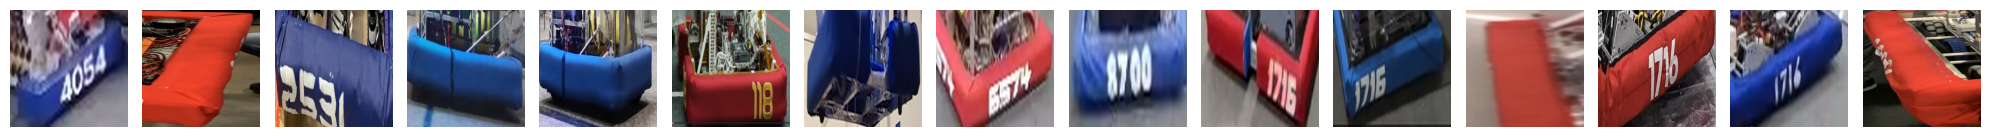

In [4]:
exts = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp")
guide_paths = []
for ext in exts:
    guide_paths.extend(glob.glob(os.path.join(GUIDE_FOLDER, ext)))
guide_paths = sorted(set(guide_paths))

print(f"Found {len(guide_paths)} guide image(s)")
for p in guide_paths:
    print(f"  {p}")

if not guide_paths:
    print(f"No guide images found in {GUIDE_FOLDER}. Add at least one image and rerun.")
    raise SystemExit(1)

guide_imgs = load_images(guide_paths, size=IMG_SIZE)
plot_images(guide_imgs)

## Load test image

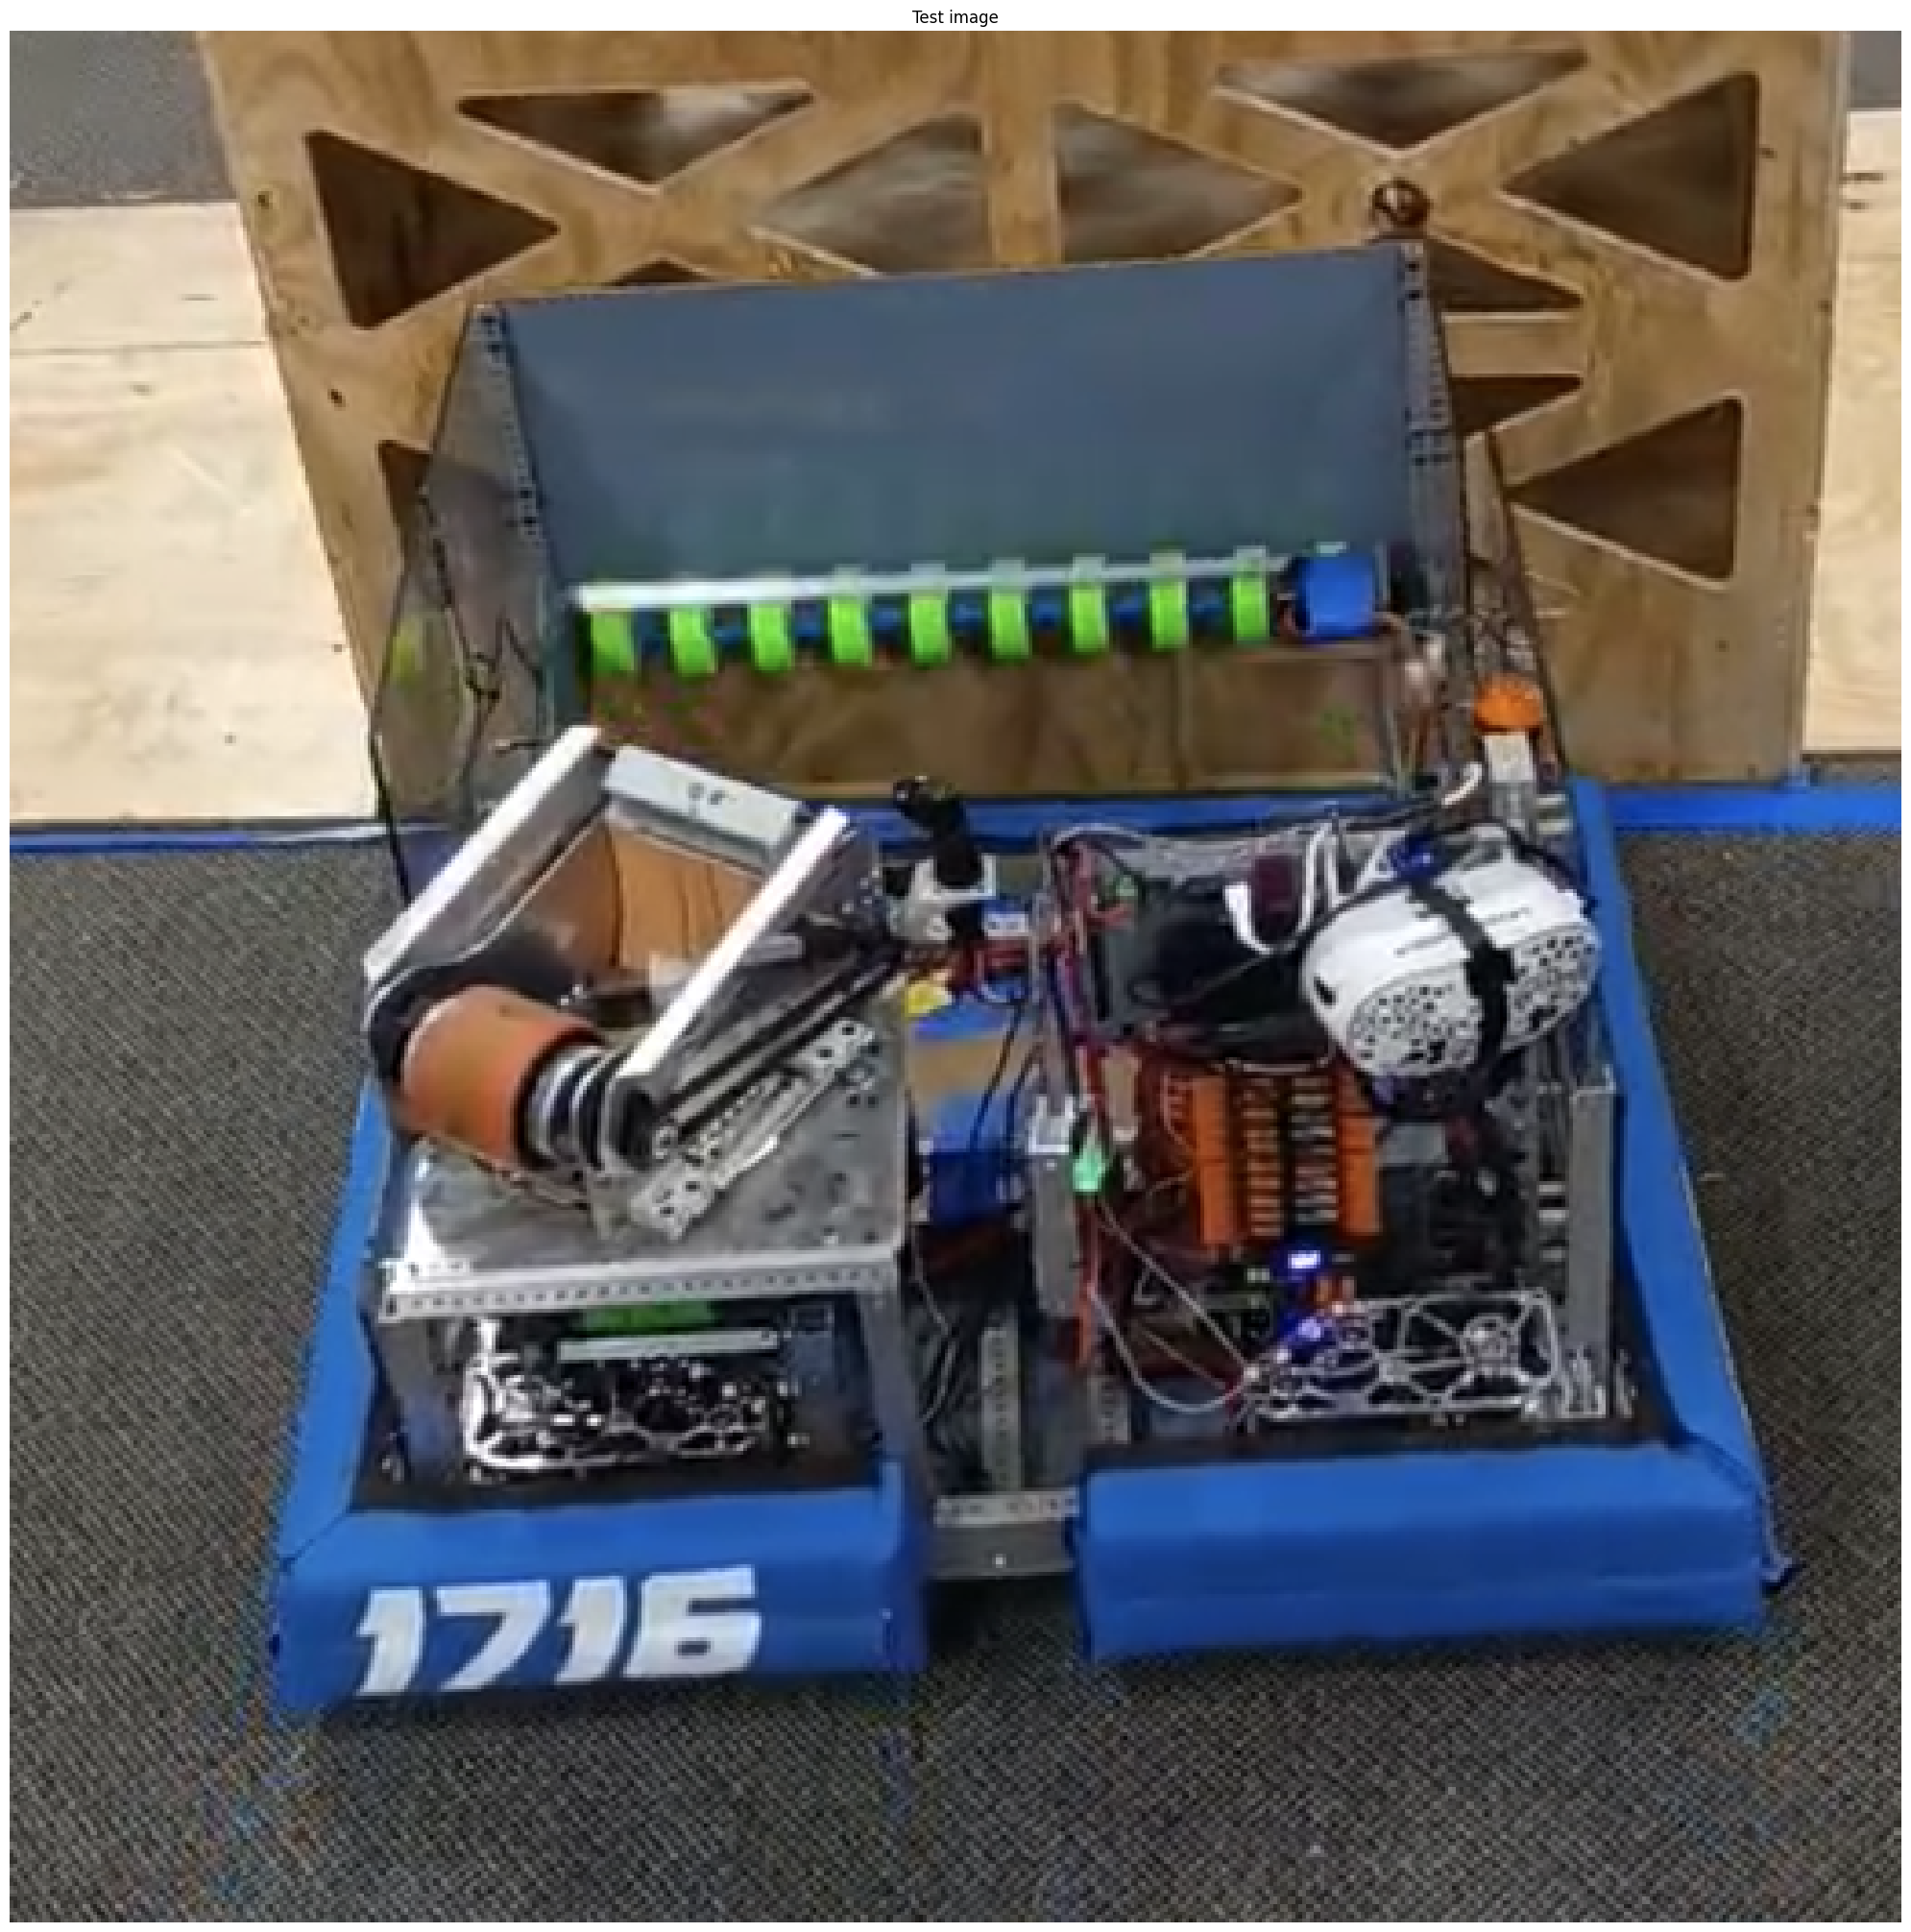

In [5]:
test_img = load_images([TEST_IMAGE], size=IMG_SIZE)[0]
plot_images([test_img], labels=["Test image"])

## Load DINOv2 model

First run will download the weights from HuggingFace (~350 MB for dinov2-base).


In [6]:
processor = AutoImageProcessor.from_pretrained(
    DINO_MODEL_ID, do_center_crop=False, do_resize=False,
)
model = Dinov2Model.from_pretrained(DINO_MODEL_ID).to(device)
model.eval()
print("Model loaded!")

Loading weights:   0%|          | 0/727 [00:00<?, ?it/s]

Model loaded!


## Extract features

We encode the test image and all guides in a single forward pass so they share identical normalisation.


In [7]:
all_imgs = [test_img] + guide_imgs
print(f"Encoding {len(all_imgs)} images ...")

all_features = get_patch_features(all_imgs, processor, model, device)
print(f"Patch features shape: {all_features.shape}")
# (1 + N_guides, num_patches, hidden_dim)

test_patches  = all_features[0].cpu()       # (num_patches, D)
guide_patches = all_features[1:].cpu()      # (N_guides, num_patches, D)

# flatten guides → (N_guides * num_patches, D)
flat_guides = guide_patches.reshape(-1, guide_patches.shape[-1])
print(f"Test patches:  {test_patches.shape}")
print(f"Guide patches: {flat_guides.shape}")

Encoding 16 images ...
Patch features shape: torch.Size([16, 1369, 1536])
Test patches:  torch.Size([1369, 1536])
Guide patches: torch.Size([20535, 1536])


## PCA on guide features

Thresholded PCA isolates the **dominant shared feature** across all guide images.
Patches whose PC1 projection is negative get zeroed out — they don't contribute to the shared feature.


In [8]:
guide_pca = thresholded_pca(flat_guides)

# keep only the non-zero (thresholded) guide patches
keep_mask = guide_pca.sum(dim=-1) > 0
filtered_guides = flat_guides[keep_mask]
print(f"Kept {filtered_guides.shape[0]} / {flat_guides.shape[0]} guide patches after threshold")

Kept 12728 / 20535 guide patches after threshold


## Combined PCA — match test image to guide feature

We concatenate the test patches with the filtered guide patches and run PCA again.
The test patches that project strongly onto the shared guide-feature dimensions
will light up in the resulting heatmap.


In [9]:
# ── With filtered guides (thresholded) ────────────────────────────────
combined = torch.cat([test_patches, filtered_guides], dim=0)
pca_result = thresholded_pca(combined)
test_pca_filtered = pca_result[:test_patches.shape[0]]

# ── With all guide patches (unfiltered, for comparison) ──────────────
combined_unfilt = torch.cat([test_patches, flat_guides], dim=0)
pca_unfilt = thresholded_pca(combined_unfilt)[:test_patches.shape[0]]

# reshape to spatial grids
n_patches = test_patches.shape[0]
grid_h = grid_w = int(math.sqrt(n_patches))
assert grid_h * grid_w == n_patches, f"Patch count {n_patches} is not a perfect square"
heatmap_filtered   = unflatten_to_grid(test_pca_filtered, grid_h, grid_w)
heatmap_unfiltered = unflatten_to_grid(pca_unfilt, grid_h, grid_w)

print(f"Heatmap grid: {grid_h}x{grid_w}")

Heatmap grid: 37x37


## Visualise results

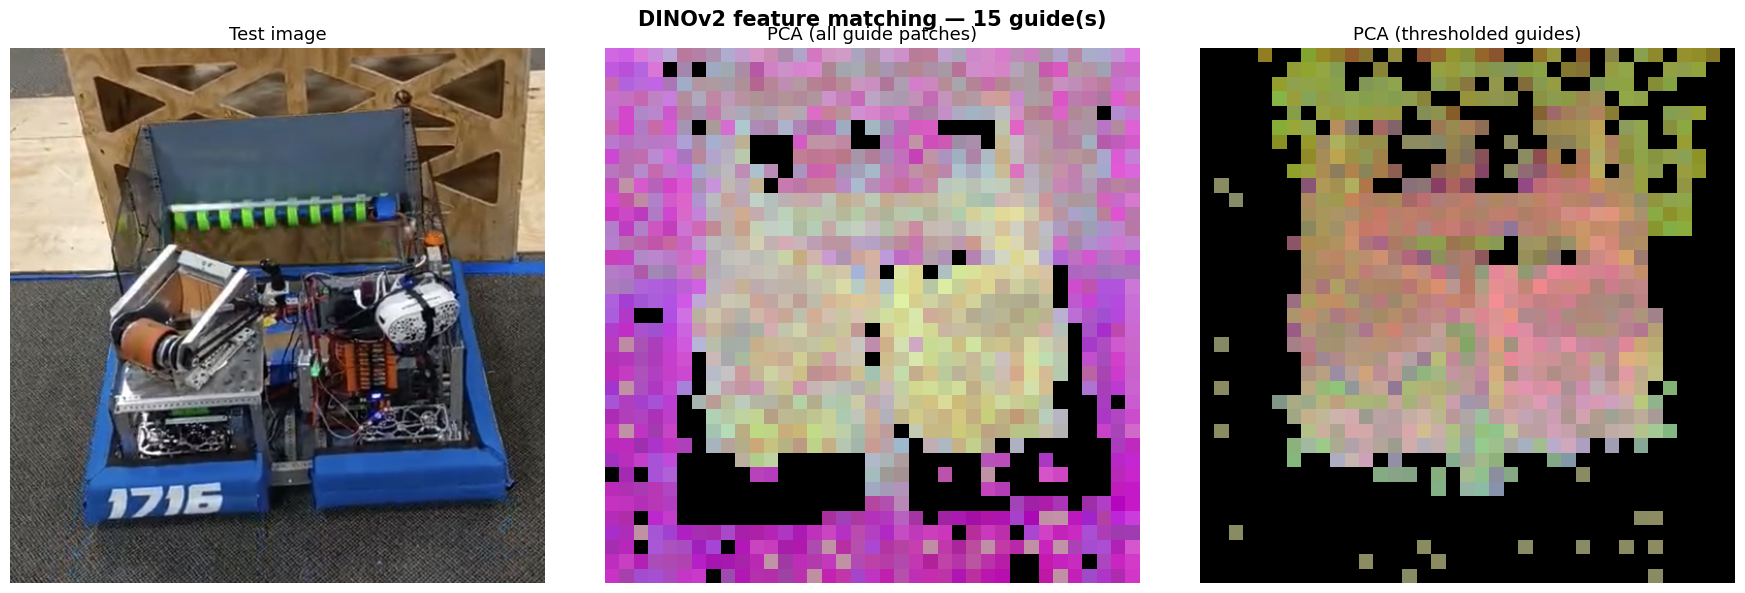

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(np.array(test_img))
axes[0].set_title("Test image", fontsize=13)
axes[0].axis("off")

axes[1].imshow(heatmap_unfiltered)
axes[1].set_title("PCA (all guide patches)", fontsize=13)
axes[1].axis("off")

axes[2].imshow(heatmap_filtered)
axes[2].set_title("PCA (thresholded guides)", fontsize=13)
axes[2].axis("off")

fig.suptitle(
    f"DINOv2 feature matching — {len(guide_paths)} guide(s)",
    fontsize=15, fontweight="bold",
)
plt.tight_layout()
plt.show()

## Overlay heatmap on original image

Upscale the PCA heatmap to the original image size and alpha-blend it on top.


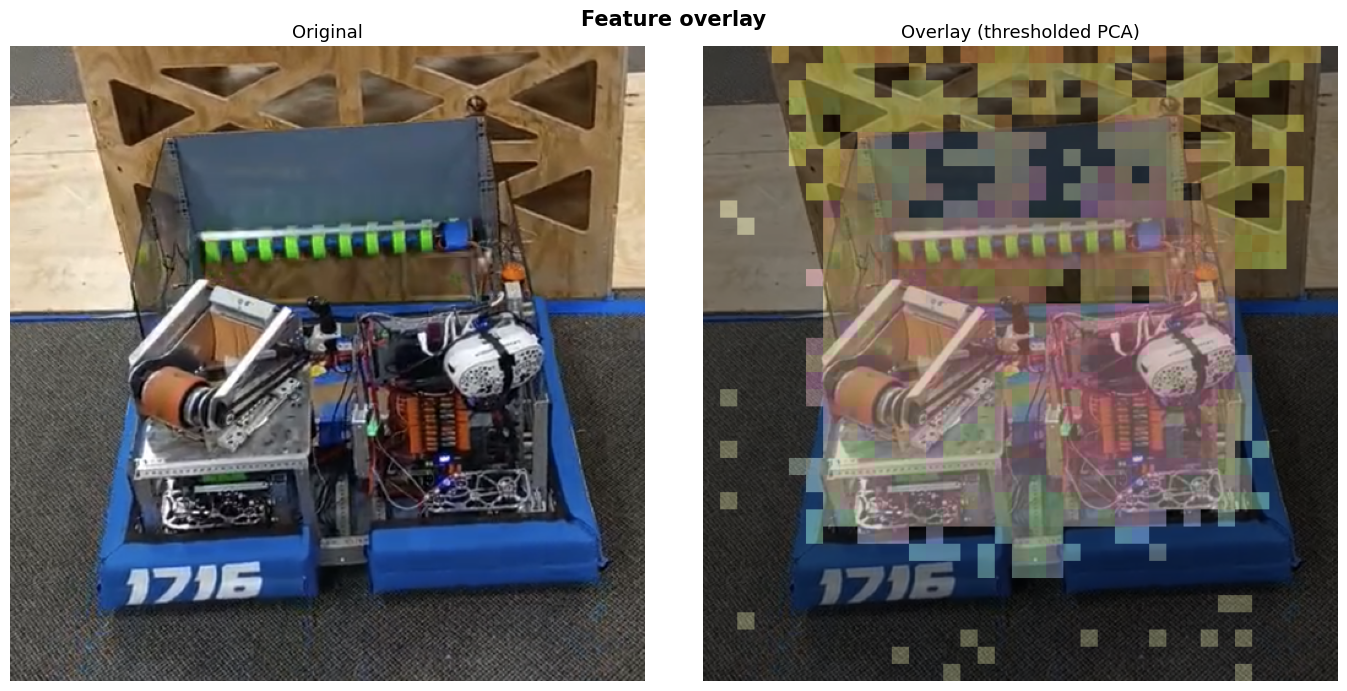

In [11]:
from PIL import Image as PILImage

# upscale heatmap to image size
heatmap_img = PILImage.fromarray((heatmap_filtered * 255).astype(np.uint8))
# Pillow 10+ moved NEAREST to Image.Resampling.NEAREST
try:
    _NEAREST = PILImage.Resampling.NEAREST
except AttributeError:
    _NEAREST = PILImage.NEAREST
heatmap_img = heatmap_img.resize((IMG_SIZE, IMG_SIZE), resample=_NEAREST)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(np.array(test_img))
axes[0].set_title("Original", fontsize=13)
axes[0].axis("off")

axes[1].imshow(np.array(test_img))
axes[1].imshow(np.array(heatmap_img), alpha=0.5)
axes[1].set_title("Overlay (thresholded PCA)", fontsize=13)
axes[1].axis("off")

plt.suptitle("Feature overlay", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()